# Persistent change at Nyandungu

Phase-1 model notebook for the Kigali wetland monitor.

The study site is Nyandungu Urban Wetland Eco-Tourism Park. Restoration works began in September 2018 and the park opened on 8 July 2022. This notebook uses a local Sentinel-2 time series to:

1. Build vegetation and water indicators and show how they are distributed.
2. Train a multilayer perceptron on the pre-restoration period so it learns the wetland's normal NDVI.
3. Keep only deviations that continue across successive observations after opening.
4. Score that result against a two-date baseline.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
from sklearn.neural_network import MLPRegressor

from src.analysis import load_cube
from src.config import CATALOG_PATH, FIGURE_DIR, MLP_PARAMS

cube = load_cube()
print("Scenes:", len(cube["dates"]))
print("Grid:", cube["ndvi"].shape, "(time, rows, columns)")
print("First / last:", cube["dates"][0], cube["dates"][-1])
print("Indices: NDVI (vegetation), NDWI (McFeeters water index)")
display(pd.read_csv(CATALOG_PATH))

Scenes: 38
Grid: (38, 400, 570) (time, rows, columns)
First / last: 2017-02-07 2026-06-30
Indices: NDVI (vegetation), NDWI (McFeeters water index)


,date,item_id,cloud_cover,mgrs,clear_fraction
0,2017-02-07,S2A_35MRT_20170207_0_L2A,10.729703,MGRS-35MRT,0.933
1,2017-06-27,S2A_35MRT_20170627_0_L2A,2.398164,MGRS-35MRT,0.928
2,2017-07-02,S2B_35MRT_20170702_0_L2A,0.036788,MGRS-35MRT,0.993
3,2017-12-29,S2B_35MRT_20171229_0_L2A,9.565566,MGRS-35MRT,0.992
4,2018-03-09,S2B_35MRT_20180309_1_L2A,3.021573,MGRS-35MRT,0.992
5,2018-06-12,S2A_35MRT_20180612_1_L2A,0.139376,MGRS-35MRT,0.990
6,2018-08-16,S2B_35MRT_20180816_1_L2A,0.108181,MGRS-35MRT,0.994
7,2018-11-19,S2A_35MRT_20181119_0_L2A,7.039563,MGRS-35MRT,0.989
8,2019-02-27,S2A_35MRT_20190227_0_L2A,2.498741,MGRS-35MRT,0.990
9,2019-04-08,S2A_35MRT_20190408_0_L2A,8.334339,MGRS-35MRT,0.989


## Data engineering

Scenes come from Sentinel-2 L2A. One clear scene is kept per quarter when at least 55 percent of the study window is free of cloud, shadow, and cirrus. The scene classification layer supplies that mask.

For every clear pixel:

- NDVI = (NIR − red) / (NIR + red)
- NDWI = (green − NIR) / (green + NIR)

Pixels inside the OpenStreetMap boundary of the park are the wetland. Pixels outside it are the control. The model is trained only on park pixels from dates before 1 September 2018.

## Model architecture

The model is a regression network. It predicts the NDVI that a pixel should have on a given day if the wetland is still in its pre-restoration state.

| Piece | Setting |
| --- | --- |
| Inputs | sin(day of year), cos(day of year), sin(2 × day of year), cos(2 × day of year), pre-restoration median NDVI, pre-restoration median NDWI |
| Hidden layer 1 | 64 units, ReLU |
| Hidden layer 2 | 32 units, ReLU |
| Output | 1 unit, linear, the expected NDVI |
| Optimizer | Adam, learning rate 0.001 |
| Loss | Squared error |
| Regularisation | L2 penalty 0.0001 and early stopping |

A date is anomalous when the absolute residual reaches a threshold chosen on tuning blocks. A pixel is a persistent change when the anomaly continues for several successive post-opening observations. The two-date baseline uses one pre-restoration scene and one post-opening scene, with no seasonal model and no persistence check.

In [2]:
seasonal_mlp = MLPRegressor(**MLP_PARAMS)
print("Hidden layers:", seasonal_mlp.hidden_layer_sizes)
print("Activation:", seasonal_mlp.activation)
print("Optimizer:", seasonal_mlp.solver)
print("Learning rate:", seasonal_mlp.learning_rate_init)
print("Early stopping:", seasonal_mlp.early_stopping)
print("Output activation: linear, because the target is continuous NDVI")
print("Loss: squared error")

Hidden layers: (64, 32)
Activation: relu
Optimizer: adam
Learning rate: 0.001
Early stopping: True
Output activation: linear, because the target is continuous NDVI
Loss: squared error


In [3]:
from src.analysis import run_analysis

summary = run_analysis()
metrics = summary["metrics"]
rows = []
for name in ("model", "baseline"):
    row = {"method": name}
    row.update({key: round(metrics[name][key], 3) for key in ("precision", "recall", "f1", "accuracy", "iou")})
    rows.append(row)
display(pd.DataFrame(rows))
print("Persistent hectares inside the park:", round(metrics["area_hectares"]["detected_persistent_inside_park"], 1))
print("Training samples:", metrics["training"]["n_samples"])
print("Iterations:", metrics["architecture"]["n_iter"])

C:\Users\HP ENVY\OneDrive\Desktop\Mission-Capstone-Project\src\analysis.py:129: RuntimeWarning: All-NaN slice encountered
  pre_median_ndvi = np.nanmedian(pre_ndvi, axis=1)
C:\Users\HP ENVY\OneDrive\Desktop\Mission-Capstone-Project\src\analysis.py:130: RuntimeWarning: All-NaN slice encountered
  pre_median_ndwi = np.nanmedian(pre_ndwi, axis=1)


{
  "model": {
    "precision": 0.2328963907344227,
    "recall": 0.8994452149791956,
    "f1": 0.3699900156896306,
    "accuracy": 0.9367264496905798,
    "iou": 0.22698634931746586,
    "support": 69808,
    "positives": 1442,
    "threshold": 0.09824000298976898,
    "min_consecutive": 3,
    "confusion_matrix": [
      [
        64094,
        4272
      ],
      [
        145,
        1297
      ]
    ]
  },
  "baseline": {
    "precision": 0.12734296752038918,
    "recall": 0.6171983356449375,
    "f1": 0.21112560787569684,
    "accuracy": 0.9047243868897548,
    "iou": 0.11802148256199443,
    "support": 69808,
    "positives": 1442,
    "threshold": 0.1,
    "pre_date": "2018-08-16",
    "post_date": "2022-07-11",
    "confusion_matrix": [
      [
        62267,
        6099
      ],
      [
        552,
        890
      ]
    ]
  },
  "area": {
    "detected_persistent_window": 292.1,
    "detected_persistent_inside_park": 62.36,
    "park": 127.54
  }
}


,method,precision,recall,f1,accuracy,iou
0,model,0.233,0.899,0.370,0.937,0.227
1,baseline,0.127,0.617,0.211,0.905,0.118


Persistent hectares inside the park: 62.4
Training samples: 41442
Iterations: 78


## Visual diagnostics and initial metrics

The histograms compare the park before the works and after opening. The time series should rise through the restoration and then stay up. The residual series is the part the persistence rule uses. Scores below are from held-out map blocks.

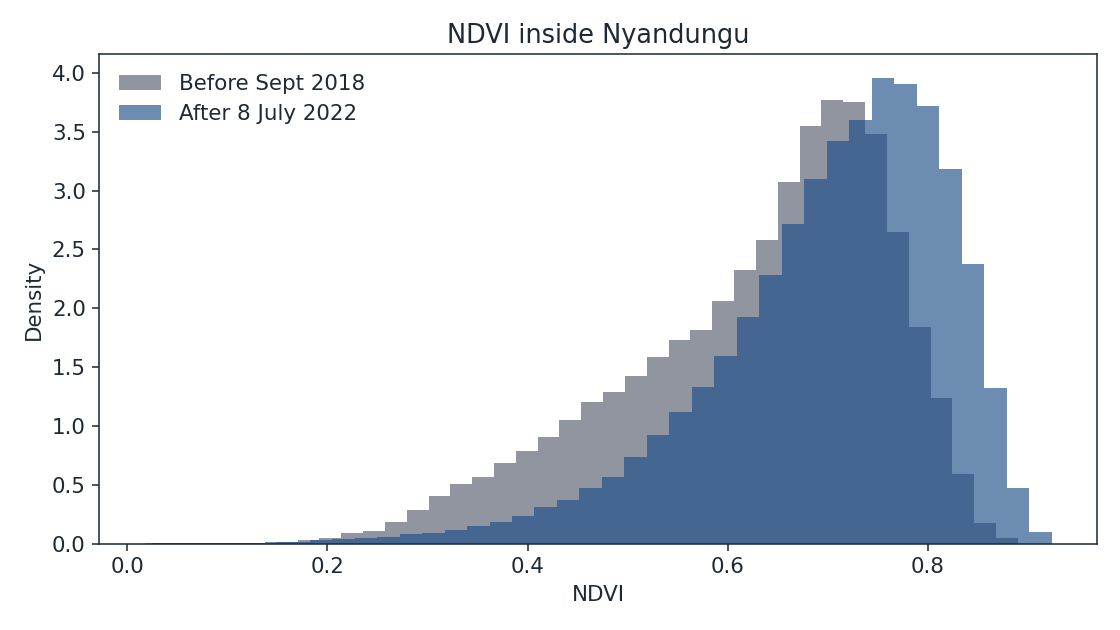

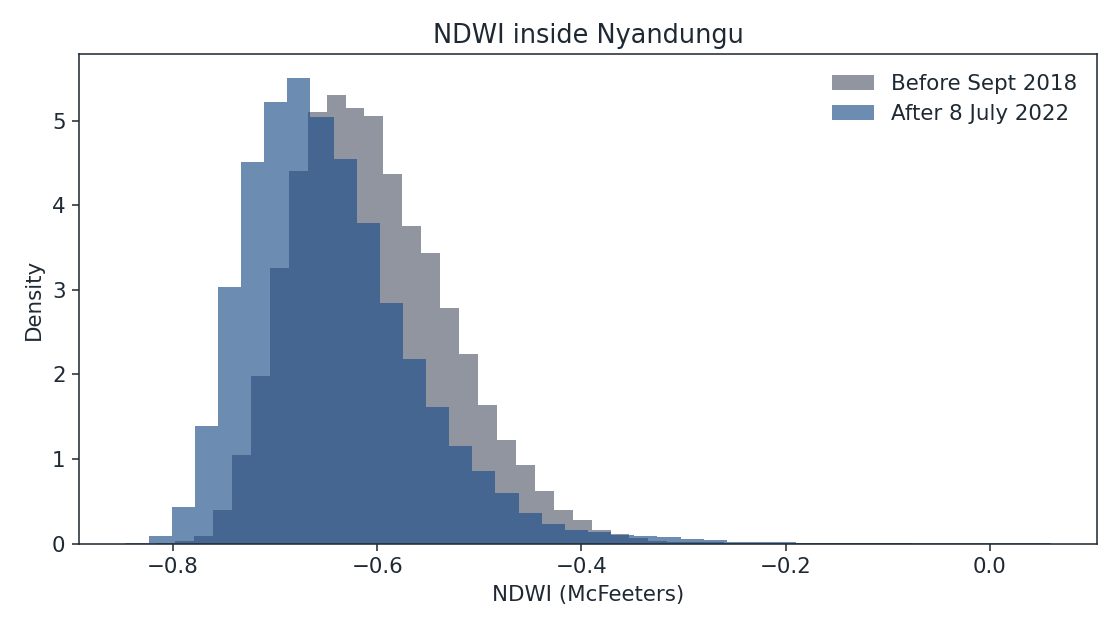

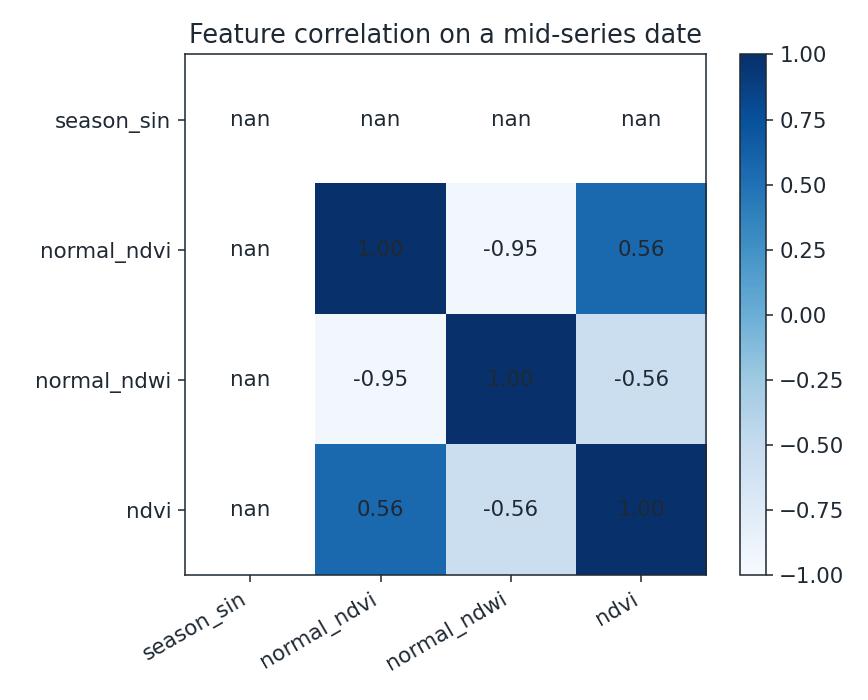

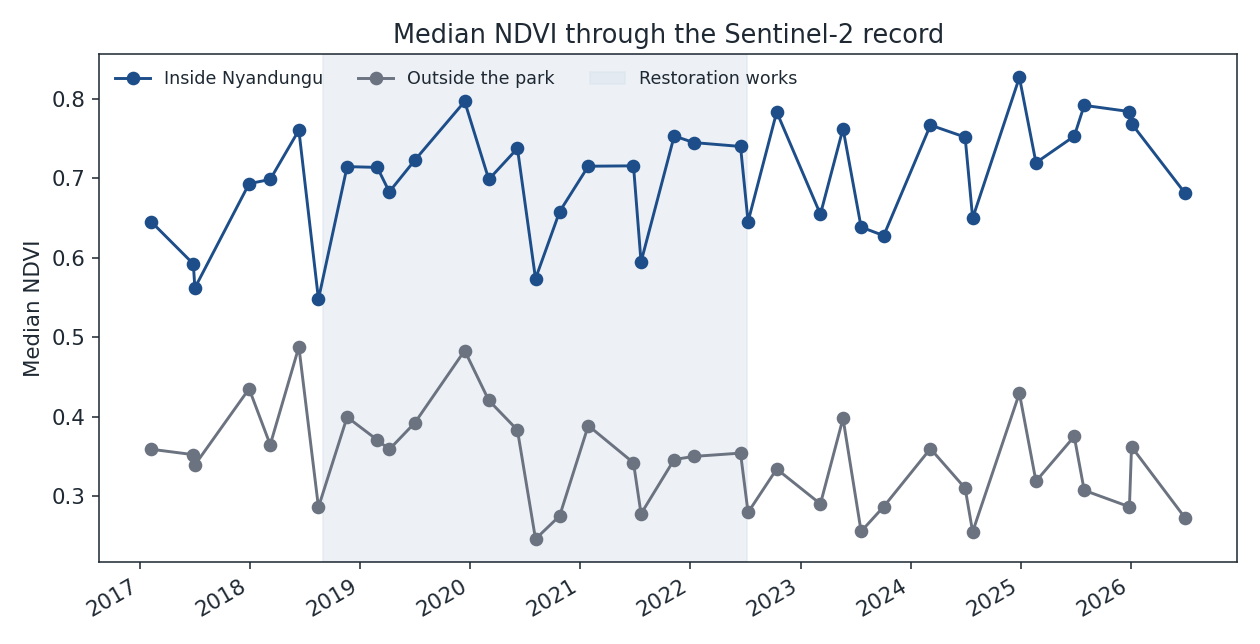

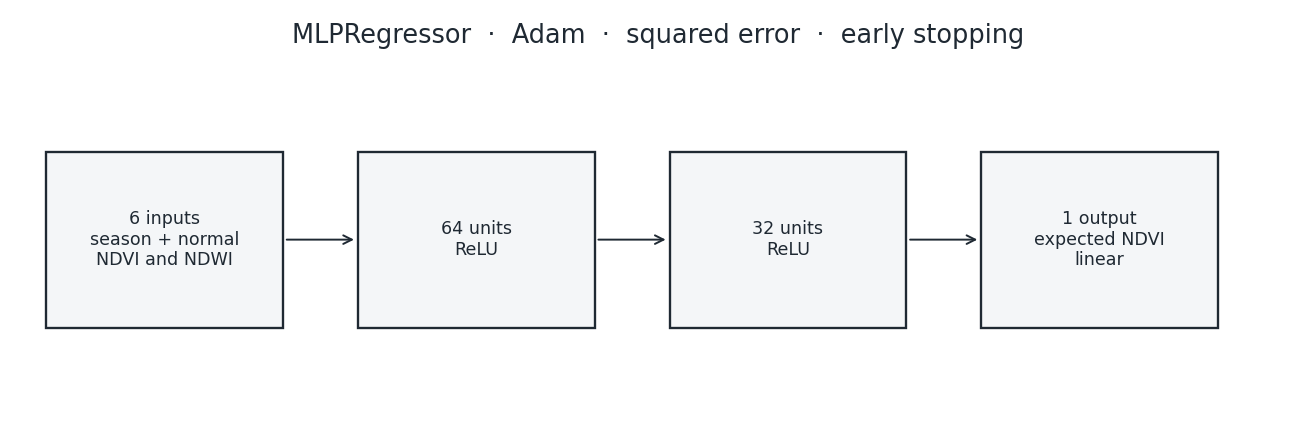

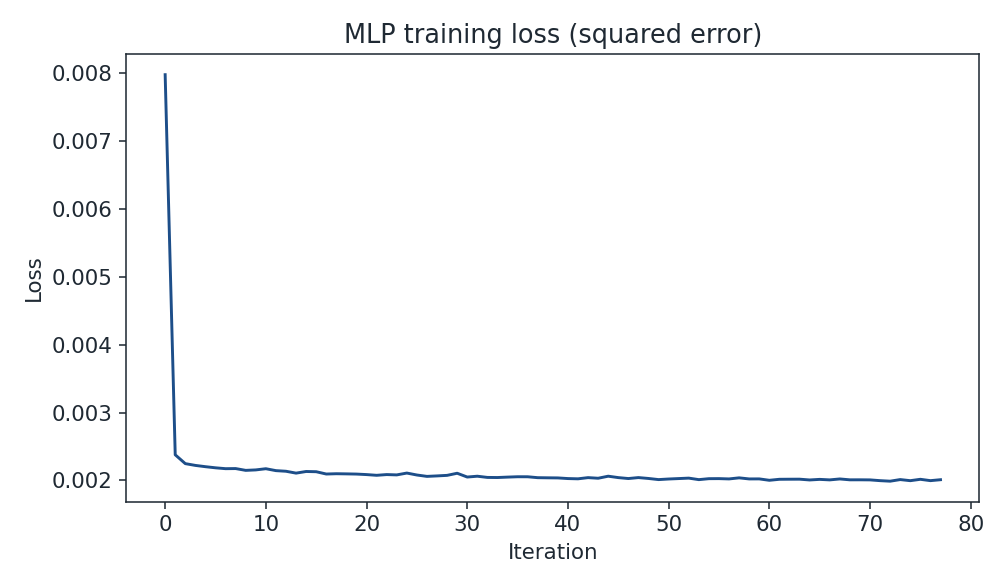

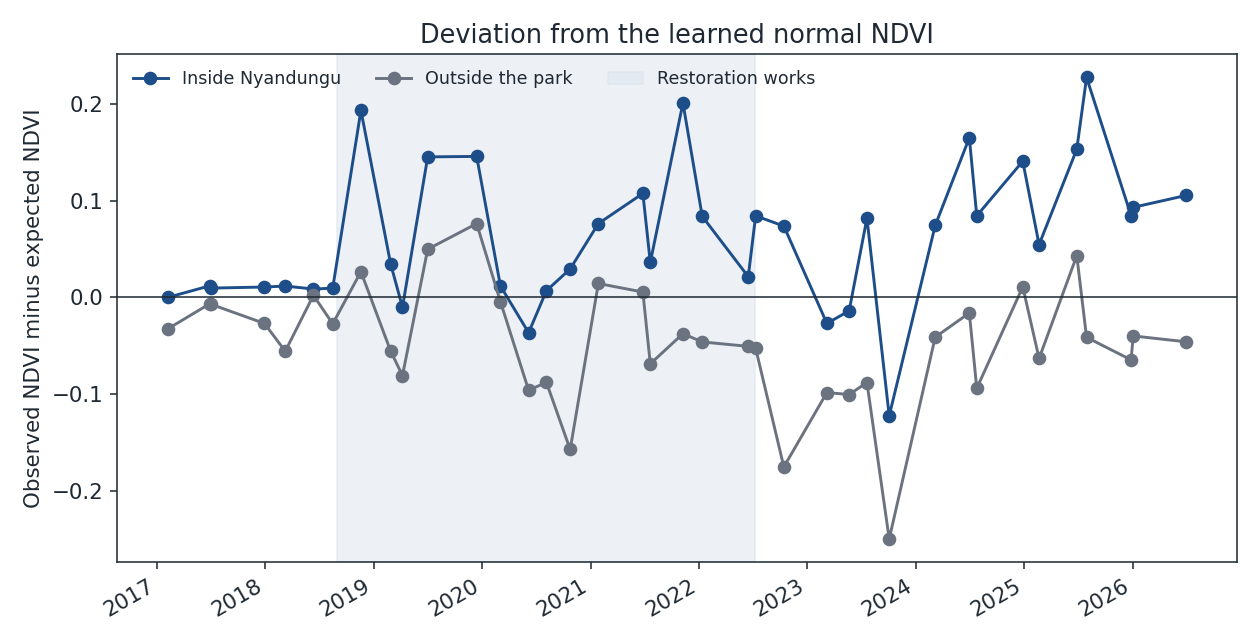

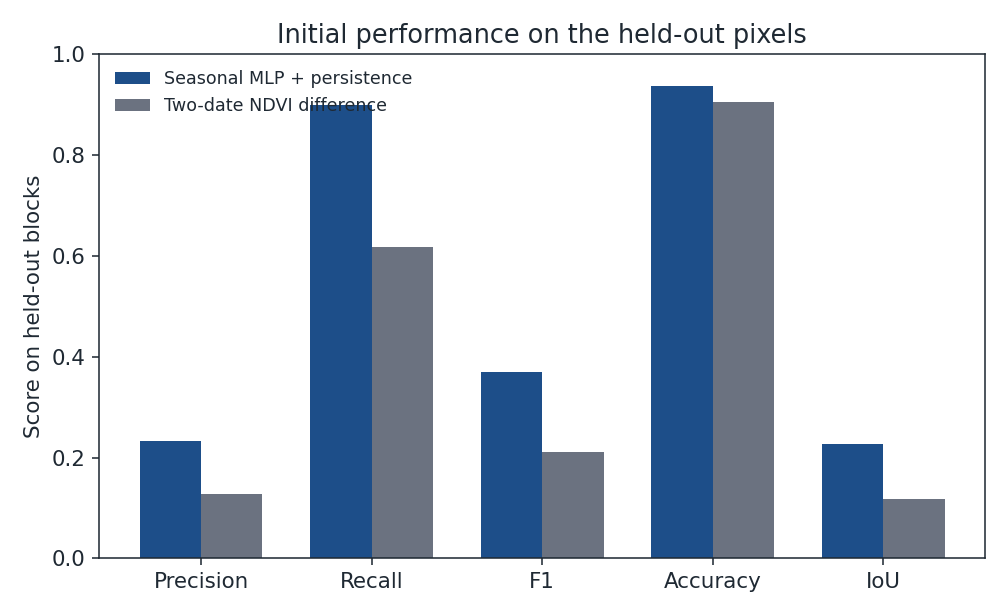

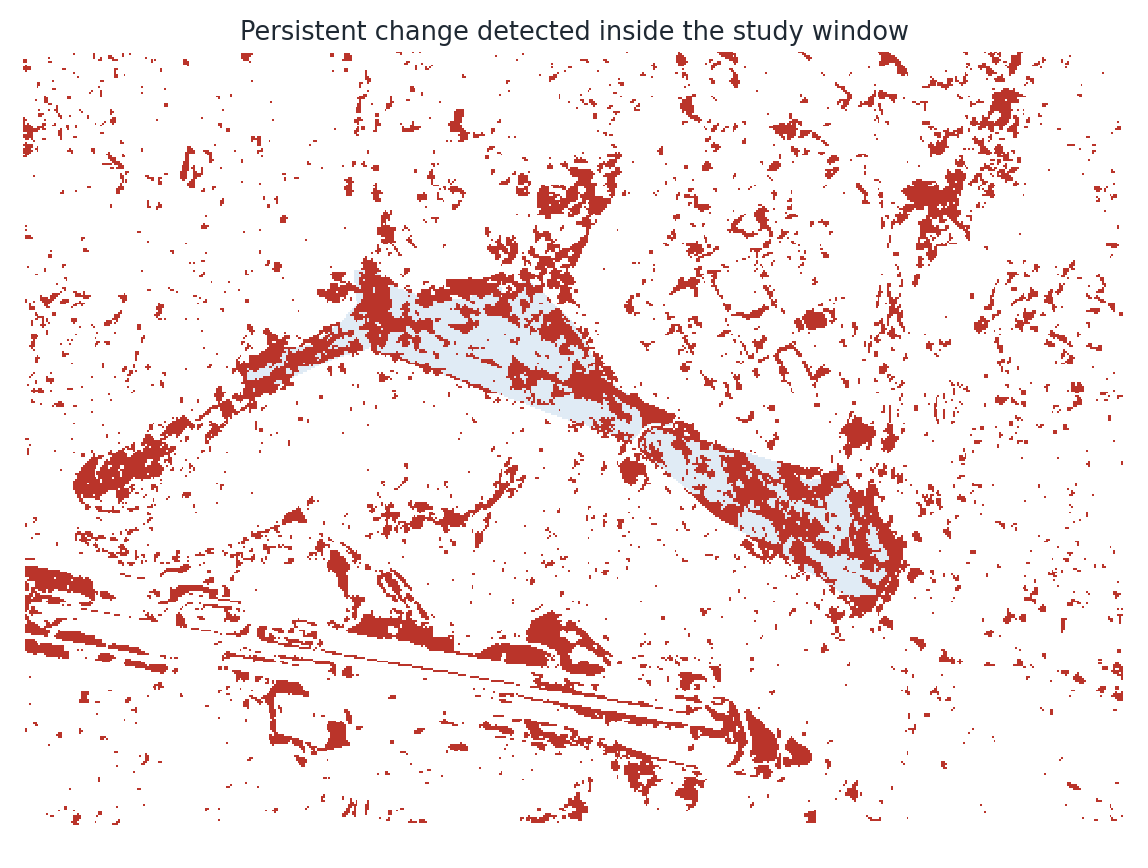

In [ ]:
for name in [
    "ndvi_distribution.png",
    "ndwi_distribution.png",
    "correlation.png",
    "ndvi_timeseries.png",
    "architecture.png",
    "loss_curve.png",
    "residual_timeseries.png",
    "metrics.png",
    "change_map.png",
]:
    display(Image(filename=str(FIGURE_DIR / name)))